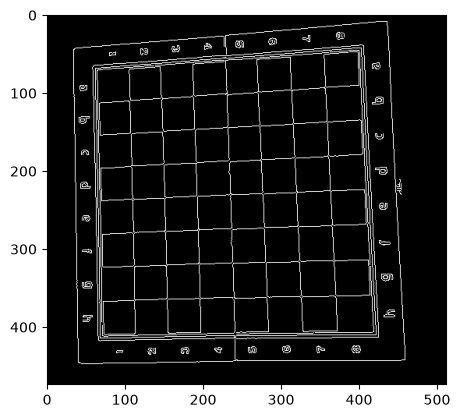

(116, 2)


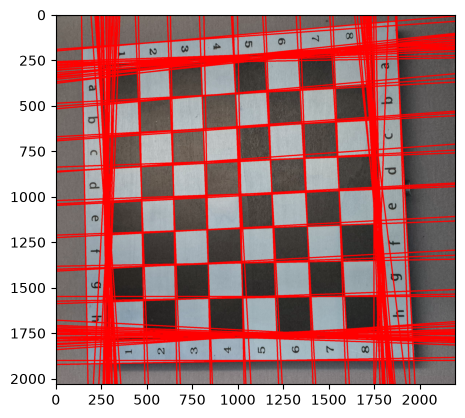

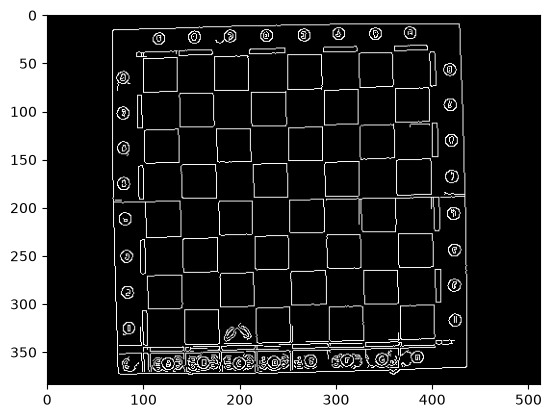

(166, 2)


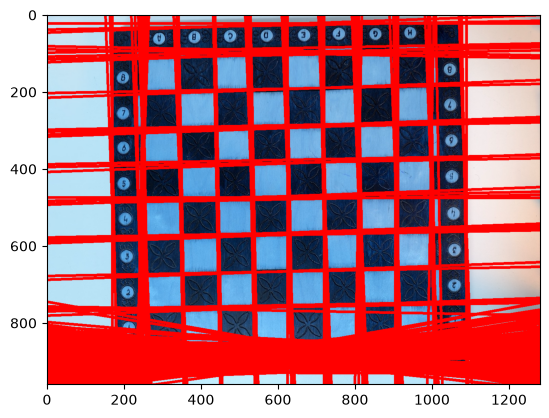

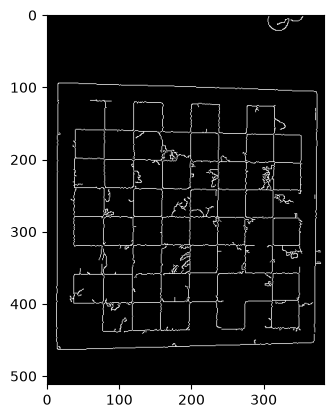

(48, 2)


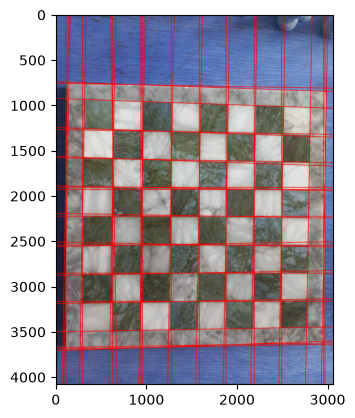

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

from chess_tracker.config import PROJECT_ROOT


def draw_line(img, r, theta):
    # Stores the value of cos(theta) in a
    a = np.cos(theta)
    # Stores the value of sin(theta) in b
    b = np.sin(theta)

    # x0 stores the value rcos(theta)
    x0 = a * r

    # y0 stores the value rsin(theta)
    y0 = b * r

    # x1 stores the rounded off value of (rcos(theta)-1000sin(theta))
    x1 = int((x0 + 1000 * (-b)) / s)

    # y1 stores the rounded off value of (rsin(theta)+1000cos(theta))
    y1 = int((y0 + 1000 * (a)) / s)

    # x2 stores the rounded off value of (rcos(theta)+1000sin(theta))
    x2 = int((x0 - 1000 * (-b)) / s)

    # y2 stores the rounded off value of (rsin(theta)-1000cos(theta))
    y2 = int((y0 - 1000 * (a)) / s)

    # cv2.line draws a line in img from the point(x1,y1) to (x2,y2).
    # (0,0,255) denotes the colour of the line to be
    # drawn. In this case, it is red.
    cv2.line(img, (x1, y1), (x2, y2), (255, 0, 0), 5)


EDGE_IMAGE_SIZE = 512

images = PROJECT_ROOT / "data" / "chess"
empty_boards = [r for r in images.glob("*/0.*") if r.is_file()]
for empty_board in empty_boards:
    img = np.array(cv2.imread(empty_board))
    # img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    s = EDGE_IMAGE_SIZE / max(img.shape[:2])
    # INTER_AREA works as blur
    edge_img = cv2.resize(src=img, dsize=None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    edges = cv2.Canny(edge_img, 100, min(edge_img.shape[:2]))
    plt.imshow(edges, cmap="gray")
    plt.show()
    lines = np.array(cv2.HoughLines(edges, 1, np.pi / 180, 80), dtype=np.float64).flatten().reshape((-1, 2))
    print(lines.shape)
    kept_lines = []
    for r_theta in lines:
        r, theta = r_theta
        # normalize
        if r_theta[1] > (3 * np.pi) / 4:
            r = -1 * r
            theta = theta - np.pi

        r_FACTOR = 1.5
        theta_FACTOR = 1.5

        kept_line_found = False
        for kept_line in kept_lines:
            if r * r_FACTOR < kept_line[0] and r * (1 / r_FACTOR) > kept_line[0] and theta * theta_FACTOR < kept_line[
                1] and theta * (1 / theta_FACTOR) > kept_line[1]:
                kept_line_found = True
        if kept_line_found:
            # skip this r and theta
            continue

        kept_lines.append([r, theta])
        draw_line(img, r, theta)
    plt.imshow(img)
    plt.show()